# 01 · Data Investigation: Predicting NBA Home-Team Wins

**CIS 4930 Intro to ML, term project.** Goal: predict `HOME_TEAM_WINS` for an NBA game using **only information available before tip-off**.

**Data:** Kaggle *"NBA games data"* by Nathan Lauga, in `src/dataset/` (read-only, never modified here).

This notebook covers data understanding only. The only "model" is the **majority-class baseline**.

| Section | Question |
|---|---|
| **A** | What is in each file: shape, columns, meaning, missing values, duplicates, memory, date range? |
| **B** | Data-quality problems: duplicates, missing stats, DNP rows, standings codes, ID consistency |
| **C** | Target balance, games per season, time-based train/validation/test split, majority baseline |
| **D** | Exploratory visuals: home-court advantage, scoring trends, team win rates, rest days, correlations |
| **E** | Leakage: which columns are same-game results and why they cannot be features |
| **F** | Feasibility: prototype every planned pre-game feature, with assert-based leakage tests |
| **G** | Open questions and risks for the professor |

Reusable code lives in `src/data_loading.py` (loading, descriptions, cleaning, splits) and `src/features_prototype.py` (pre-game features and leakage tests).

## 0. Setup

In [1]:
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from IPython.display import display

# Make `src` importable whether the notebook runs from the repo root or from notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src import data_loading as dl
from src import features_prototype as fp

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 110)

# Chart style: thin marks, hairline grid, fixed categorical order (blue, orange, aqua)
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, "#f0efec", RED])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
    "lines.linewidth": 2, "font.family": "sans-serif",
})
print("Repo root:", ROOT)
print("pandas", pd.__version__, "| seaborn", sns.__version__)

Repo root: D:\cis4930-nba-ml-project
pandas 3.1.0 | seaborn 0.13.2


## A. Overview of every file

`load_all_raw()` reads the five CSVs exactly as shipped. The table below gives one row per file. Duplicates here mean **fully identical rows**; duplicate *keys* are covered in section B.

In [2]:
raw = dl.load_all_raw()
overview = pd.DataFrame([dl.file_overview(df, name) for name, df in raw.items()]).set_index("file")

# games_details has no date column: take its date range from the games it joins to
detail_dates = pd.to_datetime(raw["games"].drop_duplicates("GAME_ID").set_index("GAME_ID")
                              .loc[raw["games_details"].GAME_ID.unique(), "GAME_DATE_EST"])
overview.loc["games_details.csv", "date_range"] = f"{detail_dates.min():%Y-%m-%d} to {detail_dates.max():%Y-%m-%d} (via games.csv)"
overview.loc["teams.csv", "date_range"] = "static snapshot (~2019-20)"
overview

,rows,columns,memory_MB,duplicate_rows,date_range
file,,,,,
games.csv,26651,21,7.1,0,2003-10-05 to 2022-12-22
games_details.csv,668628,29,340.6,0,2003-10-05 to 2022-12-22 (via games.csv)
ranking.csv,210342,13,80.4,0,2003-10-01 to 2022-12-22
players.csv,7228,4,0.6,0,seasons 2009 to 2019
teams.csv,30,14,0.0,0,static snapshot (~2019-20)


### A.1 `games.csv`: one row per game (the modeling table)
Each row is a game: date, the two teams, the **final box score of both teams**, and the target `HOME_TEAM_WINS`.

In [3]:
dl.column_table(raw["games"], "games")

,dtype,description,missing,missing_%,n_unique
GAME_DATE_EST,str,Game date (US Eastern time).,0,0.00,4304
GAME_ID,int64,"Unique game id. 1st digit = game type (1 preseason, 2 regular, 4 playoffs, 5 play-in), next 2 = season, la...",0,0.00,26622
GAME_STATUS_TEXT,str,Game status; 'Final' for every row.,0,0.00,1
HOME_TEAM_ID,int64,"Home team id (franchise id, stable across relocations).",0,0.00,30
VISITOR_TEAM_ID,int64,Away (visiting) team id.,0,0.00,30
SEASON,int64,Season start year (2022 = the 2022-23 season).,0,0.00,20
TEAM_ID_home,int64,Home team id again (redundant copy of HOME_TEAM_ID).,0,0.00,30
PTS_home,float64,Points scored by the home team in this game.,99,0.37,100
FG_PCT_home,float64,Home field-goal percentage in this game (0-1).,99,0.37,404
FT_PCT_home,float64,Home free-throw percentage in this game (0-1).,99,0.37,410


### A.2 `games_details.csv`: one row per player per game (box scores)
Each row is one player's stat line for one game. Every stat is a **same-game** value, so it is usable only after aggregation over *earlier* games.

In [4]:
dl.column_table(raw["games_details"], "games_details")

,dtype,description,missing,missing_%,n_unique
GAME_ID,int64,Game id (joins to games.csv).,0,0.00,26523
TEAM_ID,int64,Team the player played for in this game.,0,0.00,30
TEAM_ABBREVIATION,str,Team abbreviation at the time (e.g. SEA before OKC).,0,0.00,34
TEAM_CITY,str,Team city at the time.,0,0.00,33
PLAYER_ID,int64,Unique player id.,0,0.00,2687
PLAYER_NAME,str,Player full name.,0,0.00,2664
NICKNAME,str,Player nickname (rarely filled).,615591,92.07,558
START_POSITION,str,F / C / G if the player started; blank = came off the bench or did not play.,412863,61.75,3
COMMENT,str,"Why the player did not play (e.g. 'DNP - Coach's Decision', 'DND - Injury/Illness').",558939,83.59,5348
MIN,str,"Minutes played, stored as text ('MM:SS' or a plain number).",109690,16.41,3802


### A.3 `ranking.csv`: daily standings snapshots
One row per team per calendar day: wins, losses, win %, and home and road records **as of the end of that day**.

In [5]:
dl.column_table(raw["ranking"], "ranking")

,dtype,description,missing,missing_%,n_unique
TEAM_ID,int64,Team id.,0,0.0,30
LEAGUE_ID,str,"League id: NBA, written inconsistently as '0' or '00'.",0,0.0,2
SEASON_ID,int64,"1st digit = phase (1 preseason, 2 regular season), last 4 = season start year.",0,0.0,41
STANDINGSDATE,str,Date of the standings snapshot; it INCLUDES games played on that date.,0,0.0,7023
CONFERENCE,str,East or West.,0,0.0,2
TEAM,str,Team city name (e.g. 'L.A. Lakers').,0,0.0,34
G,int64,Games played so far in this phase.,0,0.0,83
W,int64,Wins so far.,0,0.0,74
L,int64,Losses so far.,0,0.0,73
W_PCT,float64,Win percentage so far (W / G).,0,0.0,895


### A.4 `players.csv`: player ↔ team ↔ season roster table

In [6]:
dl.column_table(raw["players"], "players")

,dtype,description,missing,missing_%,n_unique
PLAYER_NAME,str,Player full name.,0,0.0,1749
TEAM_ID,int64,Team the player was on.,0,0.0,30
PLAYER_ID,int64,Unique player id.,0,0.0,1769
SEASON,int64,Season start year (2009-2019 only).,0,0.0,11


### A.5 `teams.csv`: 30 current franchises (static metadata)

In [7]:
dl.column_table(raw["teams"], "teams")

,dtype,description,missing,missing_%,n_unique
LEAGUE_ID,str,League id ('00' = NBA).,0,0.00,1
TEAM_ID,int64,Team id (joins to every other file).,0,0.00,30
MIN_YEAR,int64,First season of the franchise.,0,0.00,15
MAX_YEAR,int64,Last season covered by the source (2019 for all teams: this is a snapshot).,0,0.00,1
ABBREVIATION,str,Current abbreviation.,0,0.00,30
NICKNAME,str,Team nickname (e.g. 'Hawks').,0,0.00,30
YEARFOUNDED,int64,Year founded.,0,0.00,15
CITY,str,Current city.,0,0.00,29
ARENA,str,Current arena.,0,0.00,29
ARENACAPACITY,float64,Arena capacity.,4,13.33,24


## B. Data quality

### B.1 Duplicate `GAME_ID`s in `games.csv`
No row is an exact duplicate, but some `GAME_ID`s appear twice. The check below finds how the two copies differ.

In [8]:
games_raw = raw["games"]
dup = games_raw[games_raw.GAME_ID.duplicated(keep=False)].sort_values("GAME_ID")
print(f"Extra (duplicate) rows      : {games_raw.GAME_ID.duplicated().sum()}")
print(f"Games affected              : {dup.GAME_ID.nunique()}")
print(f"Date range of affected games: {dup.GAME_DATE_EST.min()} to {dup.GAME_DATE_EST.max()} (season {sorted(dup.SEASON.unique())})")
print(f"Exact duplicate rows        : {games_raw.duplicated().sum()}")

stat_cols = dl.SAME_GAME_COLUMNS
rounded = dup.copy()
rounded[stat_cols] = rounded[stat_cols].round(3)
conflicts = rounded.groupby("GAME_ID").filter(lambda x: x[stat_cols].nunique().max() > 1)
print(f"Copies that differ only by float rounding (e.g. 0.343 vs 0.34299999): "
      f"{dup.GAME_ID.nunique() - conflicts.GAME_ID.nunique()}")
print(f"Copies with a REAL disagreement after rounding to 3 decimals        : {conflicts.GAME_ID.nunique()}")

Extra (duplicate) rows      : 29
Games affected              : 29
Date range of affected games: 2020-12-23 to 2021-01-01 (season [np.int64(2020)])
Exact duplicate rows        : 0
Copies that differ only by float rounding (e.g. 0.343 vs 0.34299999): 27
Copies with a REAL disagreement after rounding to 3 decimals        : 2


In [9]:
# Which copy is right? Recompute both games from the player box scores (after removing duplicated player rows).
details_clean = dl.clean_games_details(raw["games_details"])
kept = dl.clean_games(games_raw, drop_preseason=False, details=details_clean).set_index("GAME_ID")
for gid, grp in conflicts.groupby("GAME_ID"):
    differing = [c for c in stat_cols if grp[c].nunique() > 1]
    box = details_clean[details_clean.GAME_ID == gid].groupby("TEAM_ID")[["REB", "FGM", "FGA"]].sum()
    home, away = grp.HOME_TEAM_ID.iloc[0], grp.VISITOR_TEAM_ID.iloc[0]
    truth = {"REB_away": box.loc[away, "REB"], "REB_home": box.loc[home, "REB"],
             "FG_PCT_home": round(box.loc[home, "FGM"] / box.loc[home, "FGA"], 3),
             "FG_PCT_away": round(box.loc[away, "FGM"] / box.loc[away, "FGA"], 3)}
    print(f"GAME_ID {gid}: column {differing} -> copies {grp[differing].values.ravel().tolist()}, "
          f"box score says {[float(truth[c]) for c in differing]}, clean_games keeps {kept.loc[gid, differing].tolist()}")

GAME_ID 22000070: column ['REB_away'] -> copies [44.0, 45.0], box score says [45.0], clean_games keeps [45.0]
GAME_ID 22000076: column ['FG_PCT_home'] -> copies [0.459, 0.453], box score says [0.453], clean_games keeps [0.453]


**Handling.** `clean_games()` first rounds the percentage columns to 3 decimals, which removes the float noise. For the two real conflicts it keeps the copy that **matches the player box scores**, then drops the other copy. The conflicts are small (one rebound, 0.006 FG%), and these stats only enter rolling averages of *earlier* games, so the label is never affected.

### B.2 The 99 games with missing stats

In [10]:
missing = games_raw[games_raw.PTS_home.isna()]
print("Rows with missing stats:", len(missing))
print("Columns that are missing:", missing.columns[missing.isna().all()].tolist())
print("Seasons:", missing.SEASON.value_counts().to_dict())
print("Game type (from GAME_ID):", dl.game_type(missing.GAME_ID).map(dl.GAME_TYPES).value_counts().to_dict())
print("Dates:", missing.GAME_DATE_EST.min(), "to", missing.GAME_DATE_EST.max(), "(2003-04 regular season began 2003-10-28)")
print("HOME_TEAM_WINS values:", missing.HOME_TEAM_WINS.value_counts().to_dict())
print("Present in games_details.csv:", missing.GAME_ID.isin(raw["games_details"].GAME_ID).sum())

Rows with missing stats: 99
Columns that are missing: ['PTS_home', 'FG_PCT_home', 'FT_PCT_home', 'FG3_PCT_home', 'AST_home', 'REB_home', 'PTS_away', 'FG_PCT_away', 'FT_PCT_away', 'FG3_PCT_away', 'AST_away', 'REB_away']
Seasons: {2003: 99}
Game type (from GAME_ID): {'Preseason': 99}
Dates: 2003-10-07 to 2003-10-24 (2003-04 regular season began 2003-10-28)
HOME_TEAM_WINS values: {0: 99}
Present in games_details.csv: 0


Your assumption was right: all 99 are from 2003. More precisely, every one is a **2003 preseason game** (Oct 7–24, 2003), none has player box scores, and **every label is 0**. That 0 is a placeholder, not a real result. If we kept these rows, they would teach the model a fake "home team loses" pattern. **Handling:** drop them, which happens anyway when preseason is excluded (next check).

### B.3 `games.csv` mixes preseason, regular season, play-in and playoffs
The first digit of `GAME_ID` gives the game type. Preseason games do not count in the standings, and starters often sit.

In [11]:
gt = games_raw.drop_duplicates("GAME_ID").assign(GAME_TYPE=lambda d: dl.game_type(d.GAME_ID).map(dl.GAME_TYPES))
type_by_season = pd.crosstab(gt.SEASON, gt.GAME_TYPE, margins=True, margins_name="Total")
type_by_season = type_by_season[["Preseason", "Regular Season", "Play-In", "Playoffs", "Total"]]
type_by_season

GAME_TYPE,Preseason,Regular Season,Play-In,Playoffs,Total
SEASON,,,,,
2003,114,1189,0,82,1385
2004,48,1230,0,84,1362
2005,113,1230,0,89,1432
2006,110,1230,0,79,1419
2007,95,1230,0,86,1411
2008,110,1230,0,85,1425
2009,112,1230,0,82,1424
2010,111,1230,0,81,1422
2011,30,990,0,84,1104


**Findings.**
- **1,774 preseason games** are mixed in. We exclude them from both training rows and feature history.
- Regular-season totals match real NBA schedules: 1,189 in 2003-04 (29 teams), 990 in 2011-12 (66-game lockout season), 1,059 in 2019-20 (COVID), 1,080 in 2020-21 (72 games; 1,109 raw rows before the 29 duplicates are removed), and 1,229 in 2012-13 (one Celtics–Pacers game cancelled).
- **2022-23 is partial**: the data ends 2022-12-22, with no playoffs.
- **2021-22 is a full 82-game season.** Its lower raw count comes only from fewer recorded preseason games.

### B.4 `games_details.csv`: missing values, DNP rows, duplicates

In [12]:
gd = raw["games_details"]
no_min = gd.MIN.isna()
stat_na = gd[["FGM", "FGA", "PTS", "REB", "AST"]].isna().all(axis=1)
print(f"Rows: {len(gd):,}")
print(f"Rows with MIN missing             : {no_min.sum():,} ({no_min.mean():.1%})")
print(f"  ... and ALL stats missing too    : {(no_min & stat_na).sum():,} (MIN and stats are missing together, always)")
print(f"  ... of which have a COMMENT      : {(no_min & gd.COMMENT.notna()).sum():,}")
print(f"Rows with MIN present but no COMMENT: {(~no_min & gd.COMMENT.isna()).sum():,} (players who played)")

c = gd.loc[no_min, "COMMENT"].fillna("").str.strip().str.upper()
reason = np.select([c.str.startswith("DNP"), c.str.startswith(("DND", "DID NOT DRESS")), c.str.startswith(("NWT", "NOT WITH TEAM"))],
                   ["DNP = did not play (mostly coach's decision)", "DND = did not dress (mostly injury)", "NWT = not with team"],
                   default="other / blank")
print("\nWhy players have no stats (COMMENT grouped by prefix; the raw text has 4,800+ spellings):")
print(pd.Series(reason).value_counts().to_string())

Rows: 668,628
Rows with MIN missing             : 109,690 (16.4%)
  ... and ALL stats missing too    : 109,690 (MIN and stats are missing together, always)
  ... of which have a COMMENT      : 109,689
Rows with MIN present but no COMMENT: 558,938 (players who played)

Why players have no stats (COMMENT grouped by prefix; the raw text has 4,800+ spellings):
DNP = did not play (mostly coach's decision)    91523
DND = did not dress (mostly injury)             13004
NWT = not with team                              5129
other / blank                                      34


In [13]:
# COMMENT has trailing-whitespace variants of the same text
print("Distinct COMMENT strings before / after .strip():", gd.COMMENT.nunique(), "/", gd.COMMENT.str.strip().nunique())

# MIN is text in several formats (digits replaced by 9 to show the pattern)
print("\nMIN formats:")
print(gd.MIN.dropna().str.replace(r"\d", "9", regex=True).value_counts().to_string())
print("Rows with negative minutes:", gd.MIN.dropna().str.startswith("-").sum())

# PLUS_MINUS is missing more often than other stats; where?
season_of = raw["games"].drop_duplicates("GAME_ID").set_index("GAME_ID").SEASON
pm_extra = gd[gd.MIN.notna() & gd.PLUS_MINUS.isna()]
print(f"\nPLUS_MINUS missing although the player played: {len(pm_extra):,} rows; by season:",
      season_of.reindex(pm_extra.GAME_ID).value_counts().sort_index().to_dict())

Distinct COMMENT strings before / after .strip(): 5348 / 4818

MIN formats:


MIN
99:99           452889
9:99             81904
99               18669
9                 4980
99.999999:99       385
9.999999:99         99
-9                  12
Rows with negative minutes: 12

PLUS_MINUS missing although the player played: 23,661 rows; by season: {2003: 369, 2004: 1180, 2005: 2874, 2006: 2759, 2007: 2347, 2008: 2652, 2009: 2694, 2010: 2672, 2011: 753, 2012: 2656, 2013: 2705}


In [14]:
# Duplicate player rows inside a game
dkey = gd.duplicated(["GAME_ID", "PLAYER_ID"], keep=False)
print(f"Duplicate (GAME_ID, PLAYER_ID) rows: {gd.duplicated(['GAME_ID','PLAYER_ID']).sum()} extra rows "
      f"across {gd.loc[dkey,'GAME_ID'].nunique()} games, GAME_IDs {gd.loc[dkey,'GAME_ID'].min()}–{gd.loc[dkey,'GAME_ID'].max()}")

teams_per_game = gd.groupby("GAME_ID").TEAM_ID.nunique()
print("Games with a TEAM_ID count other than 2:", teams_per_game[teams_per_game != 2].to_dict())

# Do player points add up to the team score in games.csv?
team_pts = details_clean.groupby(["GAME_ID", "TEAM_ID"]).PTS.sum()
g1 = raw["games"].drop_duplicates("GAME_ID").dropna(subset=["PTS_home"])
home_box = team_pts.reindex(pd.MultiIndex.from_arrays([g1.GAME_ID, g1.HOME_TEAM_ID])).to_numpy()
bad = g1[home_box != g1.PTS_home.to_numpy()]
print(f"Games where summed player PTS != PTS_home (after de-duplicating players): {len(bad)} of {len(g1):,}; "
      f"by season {bad.SEASON.value_counts().sort_index().to_dict()}")
print("Games in games.csv without any box score:", (~g1.GAME_ID.isin(gd.GAME_ID)).sum() + len(missing),
      "(= the 99 games from B.2)")

Duplicate (GAME_ID, PLAYER_ID) rows: 289 extra rows across 73 games, GAME_IDs 22000001–22000078
Games with a TEAM_ID count other than 2: {10500109: 3}


Games where summed player PTS != PTS_home (after de-duplicating players): 40 of 26,523; by season {2003: 10, 2004: 21, 2006: 2, 2014: 2, 2017: 5}
Games in games.csv without any box score: 99 (= the 99 games from B.2)


**Handling (`clean_games_details`).**
- MIN and every stat are missing together, and nearly always with a DNP/DND/NWT comment. These are **players who did not play, not data errors**. Keep them as `DID_PLAY = False` (useful later for "players unavailable" counts) and exclude them from per-player averages.
- Drop the duplicate player rows from early 2020-21. Before de-duplication they double-count team totals.
- Strip COMMENT whitespace and parse MIN text into float minutes. 12 rows have negative minutes, which we treat as errors.
- 40 box scores (mostly 2003-04 and 2004-05) do not add up to the team score. PLUS_MINUS is also missing for many players who did play, before 2014. That is one more reason our team-level features come from `games.csv`, with `games_details` as an optional extra.

### B.5 `ranking.csv`: how `SEASON_ID` works

In [15]:
rk = raw["ranking"].copy()
rk["PHASE"] = (rk.SEASON_ID // 10000).map(dl.GAME_TYPES)
rk["SEASON"] = rk.SEASON_ID % 10000
print("Phase codes present:", rk.PHASE.value_counts().to_dict(), "(no playoff code exists)")
season_codes = (rk.groupby(["SEASON", "PHASE"])
                  .agg(rows=("TEAM_ID", "size"), teams=("TEAM_ID", "nunique"),
                       first_date=("STANDINGSDATE", "min"), last_date=("STANDINGSDATE", "max"), max_G=("G", "max"))
                  .unstack("PHASE").swaplevel(axis=1).sort_index(axis=1))
season_codes

Phase codes present: {'Regular Season': 197489, 'Preseason': 12853} (no playoff code exists)


PHASE    Preseason                                Regular Season                                 
        first_date   last_date max_G   rows teams     first_date   last_date max_G     rows teams
SEASON                                                                                           
2002           NaN         NaN   NaN    NaN   NaN     2003-10-01  2003-10-04  82.0    116.0  29.0
2003    2003-10-05  2003-10-27   0.0  667.0  29.0     2003-10-28  2004-10-11  82.0  10150.0  29.0
2004    2004-10-12  2004-11-01   0.0  630.0  30.0     2004-11-02  2005-10-09  82.0  10260.0  30.0
2005    2005-10-10  2005-10-31   8.0  660.0  30.0     2005-11-01  2006-10-04  82.0  10140.0  30.0
2006    2006-10-05  2006-10-30   8.0  780.0  30.0     2006-10-31  2007-10-05  82.0  10200.0  30.0
2007    2007-10-06  2007-10-29   8.0  720.0  30.0     2007-10-30  2008-10-04  82.0  10230.0  30.0
2008    2008-10-05  2008-10-27   8.0  690.0  30.0     2008-10-28  2009-09-30  82.0  10140.0  30.0
2009    2009-10-01  2009-10-26   8.0  780.0  30.0     2009-10-27  2010-10-02  82.0  10230.0  30.0
2010    2010-10-03  2010-10-25   8.0  690.0  30.0     2010-10-26  2011-12-15  82.0  12480.0  30.0
2011    2011-12-16  2011-12-24   2.0  270.0  30.0     2011-12-25  2012-10-04  66.0   8550.0  30.0
2012    2012-10-05  2012-10-29   8.0  750.0  30.0     2012-10-30  2013-10-04  82.0  10200.0  30.0
2013    2013-10-05  2013-10-28   8.0  720.0  30.0     2013-10-29  2014-10-03  82.0  10200.0  30.0
2014    2014-10-04  2014-10-27   8.0  720.0  30.0     2014-10-28  2015-10-01  82.0  10170.0  30.0
2015    2015-10-02  2015-10-26   8.0  750.0  30.0     2015-10-27  2016-09-30  82.0  10200.0  30.0
2016    2016-10-01  2016-10-24   8.0  720.0  30.0     2016-10-25  2017-09-29  82.0  10200.0  30.0
2017    2017-09-30  2017-10-16   6.0  510.0  30.0     2017-10-17  2018-09-27  82.0  10380.0  30.0
2018    2018-09-28  2018-10-15   6.0  540.0  30.0     2018-10-16  2019-09-29  82.0  10470.0  30.0
2019    2019-09-30  2020-07-29   6.0  900.0  30.0     2019-10-22  2020-12-10  75.0  12240.0  30.0
2020    2020-12-11  2020-12-21   4.0  336.0  30.0     2020-12-22  2021-10-02  72.0   8573.0  30.0
2021    2021-10-03  2021-10-18   6.0  480.0  30.0     2021-10-19  2022-09-29  82.0  10380.0  30.0
2022    2022-09-30  2022-10-17   6.0  540.0  30.0     2022-10-18  2022-12-22  35.0   1980.0  30.0

**How it works.** `SEASON_ID = <phase digit><season start year>`: `1xxxx` = preseason, `2xxxx` = regular season.

- **There are no playoff rows.** The regular-season rows simply continue every day through the playoffs and the offseason with the **frozen final record**, until the next preseason starts.
- The `22002` rows (Oct 1–4, 2003) are leftover 2002-03 final standings.
- The `12019` rows dated July 22–29, 2020 are the bubble scrimmages. The regular-season rows pause on those days.

So `STANDINGSDATE` alone does not tell you the season: you must filter on `SEASON_ID`.

In [16]:
per_day = rk.groupby(["TEAM_ID", "STANDINGSDATE"]).size()
dups = rk[rk.duplicated(["TEAM_ID", "STANDINGSDATE"], keep=False)]
print("Rows per (team, date):", per_day.value_counts().to_dict())
print("Duplicate dates:", sorted(dups.STANDINGSDATE.unique()))
print("Do the duplicate copies ever disagree (W_PCT rounded to 3 decimals)?",
      bool((dups.assign(W_PCT=dups.W_PCT.round(3)).groupby(["TEAM_ID", "STANDINGSDATE"])
                [["SEASON_ID", "G", "W", "L", "W_PCT", "HOME_RECORD", "ROAD_RECORD"]].nunique() > 1).any().any()))
print("LEAGUE_ID spellings:", rk.LEAGUE_ID.value_counts().to_dict())
print("Distinct calendar days covered:", rk.STANDINGSDATE.nunique(), "| teams per day:",
      rk.groupby("STANDINGSDATE").TEAM_ID.nunique().value_counts().to_dict(), "(29 = 2003-04, before Charlotte joined)")
print("G == W + L everywhere:", bool((rk.G == rk.W + rk.L).all()))
print("RETURNTOPLAY filled only for:", rk.loc[rk.RETURNTOPLAY.notna(), "SEASON_ID"].unique().tolist())

Rows per (team, date): {1: 210284, 2: 29}
Duplicate dates: ['2020-12-20', '2020-12-21', '2020-12-27', '2020-12-28', '2020-12-29', '2020-12-30', '2020-12-31', '2021-01-01']


Do the duplicate copies ever disagree (W_PCT rounded to 3 decimals)? False
LEAGUE_ID spellings: {'0': 201792, '00': 8550}
Distinct calendar days covered: 7023 | teams per day: {30: 6646, 29: 377} (29 = 2003-04, before Charlotte joined)
G == W + L everywhere: True
RETURNTOPLAY filled only for: [22019]


**Does a snapshot include that day's games?** This decides whether we must use the day before. For every regular-season team-game, we compare the standings' games-played `G` with the number of games the team had actually played in `games.csv`.

In [17]:
games = dl.clean_games(raw["games"], details=details_clean)   # no dup ids, no preseason, sorted by date
ranking = dl.clean_ranking(raw["ranking"])        # regular-season rows only, no dup (team, date)
tg = dl.to_team_games(games)
tg["G_BEFORE"] = tg.groupby(["TEAM_ID", "SEASON"]).cumcount()
reg = tg[tg.GAME_TYPE == "Regular Season"]

st = ranking.set_index(["TEAM_ID", "SEASON", "STANDINGSDATE"])["G"]
same_day = st.reindex(pd.MultiIndex.from_arrays([reg.TEAM_ID, reg.SEASON, reg.GAME_DATE])).to_numpy()
prev_day = st.reindex(pd.MultiIndex.from_arrays([reg.TEAM_ID, reg.SEASON, reg.GAME_DATE - pd.Timedelta(days=1)])).to_numpy()
print(f"Same-day snapshot G == games BEFORE this game : {np.mean(same_day == reg.G_BEFORE):.2%}")
print(f"Same-day snapshot G == games INCLUDING it     : {np.mean(same_day == reg.G_BEFORE + 1):.2%}")
print(f"Previous-day snapshot G == games before it    : {np.nanmean(np.where(np.isnan(prev_day), np.nan, prev_day == reg.G_BEFORE)):.2%} "
      f"(where a same-season previous-day row exists)")

Same-day snapshot G == games BEFORE this game : 0.00%
Same-day snapshot G == games INCLUDING it     : 99.93%
Previous-day snapshot G == games before it    : 99.93% (where a same-season previous-day row exists)


⚠️ **The same-day snapshot already contains the game's result.** For the standings feature to be leakage-free, it must come from the **previous day (or earlier)**, exactly as planned.

### B.6 Do team IDs match across files?

In [18]:
team_ids = set(raw["teams"].TEAM_ID)
id_sets = {
    "games.HOME_TEAM_ID": set(games_raw.HOME_TEAM_ID), "games.VISITOR_TEAM_ID": set(games_raw.VISITOR_TEAM_ID),
    "games_details.TEAM_ID": set(gd.TEAM_ID), "ranking.TEAM_ID": set(rk.TEAM_ID), "players.TEAM_ID": set(raw["players"].TEAM_ID),
}
print(pd.DataFrame({k: {"n_ids": len(v), "not_in_teams.csv": len(v - team_ids)} for k, v in id_sets.items()}).T)
print("\nHOME_TEAM_ID == TEAM_ID_home everywhere:", bool((games_raw.HOME_TEAM_ID == games_raw.TEAM_ID_home).all()),
      "| VISITOR_TEAM_ID == TEAM_ID_away:", bool((games_raw.VISITOR_TEAM_ID == games_raw.TEAM_ID_away).all()))
print("Home team == away team anywhere:", bool((games_raw.HOME_TEAM_ID == games_raw.VISITOR_TEAM_ID).any()))
print("Every games_details GAME_ID exists in games.csv:", bool(gd.GAME_ID.isin(games_raw.GAME_ID).all()))

abbr = gd.groupby("TEAM_ID").TEAM_ABBREVIATION.unique()
print("\nFranchises whose abbreviation changed (same TEAM_ID, so history is continuous):")
print(abbr[abbr.str.len() > 1].apply(list).to_string())
players_missing = set(gd.PLAYER_ID) - set(raw["players"].PLAYER_ID)
print(f"\nPlayers in games_details but not in players.csv: {len(players_missing):,} of {gd.PLAYER_ID.nunique():,} "
      "(players.csv only covers 2009-2019)")

                       n_ids  not_in_teams.csv
games.HOME_TEAM_ID        30                 0
games.VISITOR_TEAM_ID     30                 0
games_details.TEAM_ID     30                 0
ranking.TEAM_ID           30                 0
players.TEAM_ID           30                 0

HOME_TEAM_ID == TEAM_ID_home everywhere: True | VISITOR_TEAM_ID == TEAM_ID_away: True
Home team == away team anywhere: False
Every games_details GAME_ID exists in games.csv: True

Franchises whose abbreviation changed (same TEAM_ID, so history is continuous):
TEAM_ID
1610612740    [NOP, NOH, NOK]
1610612751         [BKN, NJN]
1610612760         [OKC, SEA]

Players in games_details but not in players.csv: 918 of 2,687 (players.csv only covers 2009-2019)


### B.7 Does every game have a matching previous-day standings row?
For each non-preseason game, we look for a **same-season regular-season** row for both teams dated exactly the day before.

In [19]:
key_prev = pd.MultiIndex.from_arrays([tg.TEAM_ID, tg.SEASON, tg.GAME_DATE - pd.Timedelta(days=1)])
tg["HAS_PREV_DAY_ROW"] = key_prev.isin(st.index)
game_cov = tg.groupby("GAME_ID").HAS_PREV_DAY_ROW.all()
no_row = tg[~tg.HAS_PREV_DAY_ROW]
print(f"Games with a previous-day row for BOTH teams: {game_cov.sum():,} of {len(game_cov):,} ({game_cov.mean():.2%})")
print(f"Team-games without one: {len(no_row)}; of these, season openers (G_BEFORE == 0): {(no_row.G_BEFORE == 0).sum()}")
print("Remaining cases:")
display(no_row[no_row.G_BEFORE > 0][["GAME_ID", "GAME_DATE", "SEASON", "GAME_TYPE", "TEAM_ID", "G_BEFORE"]])

Games with a previous-day row for BOTH teams: 24,789 of 24,848 (99.76%)
Team-games without one: 118; of these, season openers (G_BEFORE == 0): 114
Remaining cases:


,GAME_ID,GAME_DATE,SEASON,GAME_TYPE,TEAM_ID,G_BEFORE
6537,21901231,2020-07-30,2019,Regular Season,1610612740,64
16561,21901232,2020-07-30,2019,Regular Season,1610612746,64
18276,21901232,2020-07-30,2019,Regular Season,1610612747,63
43056,21901231,2020-07-30,2019,Regular Season,1610612762,64


Almost all misses are **season openers**. The regular-season rows begin on opening night, so the day before only has preseason rows; the correct pre-game record there is 0–0, which `pregame_standings()` assigns.

The only other cases are the **2 games on the bubble restart day (2020-07-30)**. The day before only has scrimmage (preseason) rows, so `pregame_standings()` falls back to the latest earlier regular-season snapshot (2020-07-21). That snapshot is still correct, because no regular-season games were played in between.

### B.8 Is `games.csv` complete? Compare with the final standings

In [20]:
final_G = ranking[ranking.SEASON >= 2003].sort_values("STANDINGSDATE").groupby(["SEASON", "TEAM_ID"]).G.last()
played = reg.groupby(["SEASON", "TEAM_ID"]).size()
gap = (final_G - played.reindex(final_G.index).fillna(0)).rename("missing_games")
print("Team-seasons where standings count more games than games.csv:")
print(gap[gap != 0].to_string())
ids_2022 = set(games.loc[(games.SEASON == 2022) & (games.GAME_TYPE == "Regular Season"), "GAME_ID"])
print("Missing 2022 regular-season GAME_ID in sequence:", sorted(set(range(min(ids_2022), max(ids_2022) + 1)) - ids_2022))

Team-seasons where standings count more games than games.csv:
SEASON  TEAM_ID   
2022    1610612753    1
        1610612754    1
Missing 2022 regular-season GAME_ID in sequence: [22200236]


Apart from that one game, `games.csv` is complete. The 2022-23 game `22200236` (Orlando vs Indiana, around Nov 20, 2022) is missing. Its only effect is that `games.csv`-based season counts for those two teams lag the standings by one game.

### B.9 The cleaned modeling table

In [21]:
summary = pd.DataFrame({
    "rows": [len(games_raw), games_raw.GAME_ID.nunique(), len(kept), len(games)],
}, index=["raw games.csv", "after dropping 29 duplicate GAME_IDs", "after dropping 99 no-stat games", "after dropping preseason (= modeling table)"])
display(summary)
print(games.GAME_TYPE.value_counts().to_string())
print(f"Neutral-site 2020 bubble games (flagged, NEUTRAL_SITE=True): {games.NEUTRAL_SITE.sum()}")
print(f"Columns kept: {games.shape[1]} -> {games.columns.tolist()}")

,rows
raw games.csv,26651
after dropping 29 duplicate GAME_IDs,26622
after dropping 99 no-stat games,26523
after dropping preseason (= modeling table),24848


GAME_TYPE
Regular Season    23244
Playoffs           1591
Play-In              13
Neutral-site 2020 bubble games (flagged, NEUTRAL_SITE=True): 172
Columns kept: 21 -> ['GAME_DATE_EST', 'GAME_ID', 'HOME_TEAM_ID', 'VISITOR_TEAM_ID', 'SEASON', 'PTS_home', 'FG_PCT_home', 'FT_PCT_home', 'FG3_PCT_home', 'AST_home', 'REB_home', 'PTS_away', 'FG_PCT_away', 'FT_PCT_away', 'FG3_PCT_away', 'AST_away', 'REB_away', 'HOME_TEAM_WINS', 'GAME_DATE', 'GAME_TYPE', 'NEUTRAL_SITE']


## C. Target and splits

### C.1 Label balance

HOME_TEAM_WINS
away win (0)    10163
home win (1)    14685
Home win rate: 59.10%  (regular season only: 58.82%)


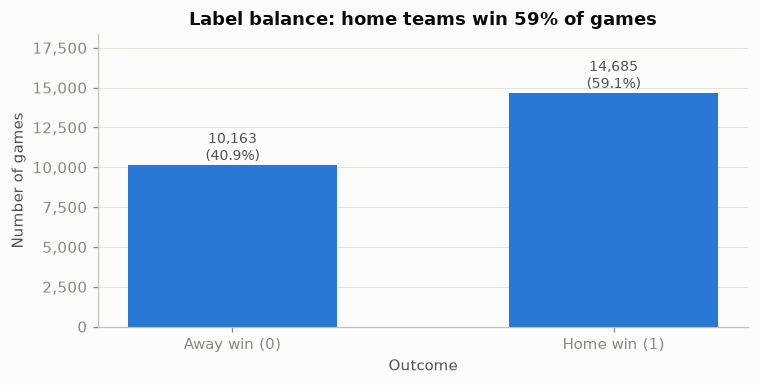

In [22]:
counts = games.HOME_TEAM_WINS.value_counts().sort_index()
print(counts.rename({0: "away win (0)", 1: "home win (1)"}).to_string())
print(f"Home win rate: {games.HOME_TEAM_WINS.mean():.2%}  (regular season only: "
      f"{games.loc[games.GAME_TYPE=='Regular Season','HOME_TEAM_WINS'].mean():.2%})")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(["Away win (0)", "Home win (1)"], counts.values, color=BLUE, width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom", color=INK2, fontsize=9)
ax.set_title("Label balance: home teams win 59% of games")
ax.set_xlabel("Outcome")
ax.set_ylabel("Number of games")
ax.set_ylim(0, counts.max() * 1.25)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### C.2 Games per season (by game type)

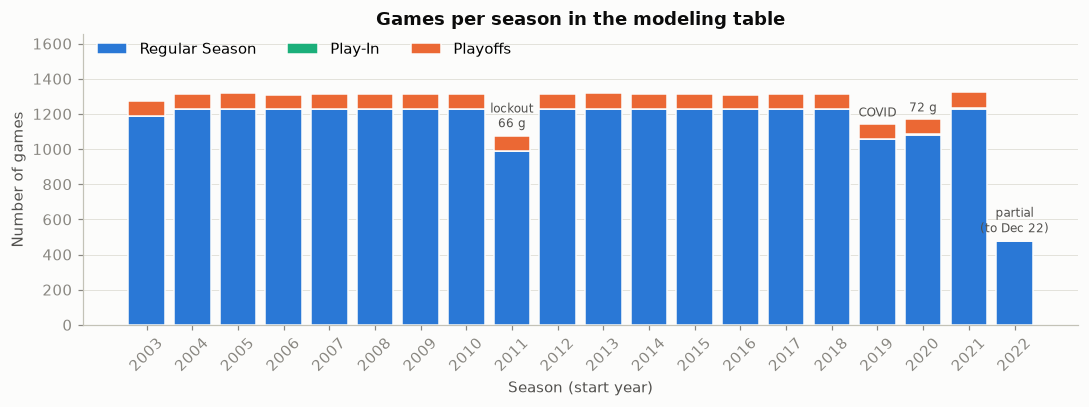

SEASON,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
GAME_TYPE,,,,,,,,,,,,,,,,,,,,
Regular Season,1189.000,1230.000,1230.000,1230.000,1230.00,1230.000,1230.000,1230.000,990.000,1229.000,1230.000,1230.000,1230.000,1230.000,1230.000,1230.000,1059.000,1080.000,1230.000,477.00
Play-In,0.000,0.000,0.000,0.000,0.00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,6.000,6.000,0.00
Playoffs,82.000,84.000,89.000,79.000,86.00,85.000,82.000,81.000,84.000,85.000,89.000,81.000,86.000,79.000,82.000,82.000,83.000,85.000,87.000,0.00
Total,1271.000,1314.000,1319.000,1309.000,1316.00,1315.000,1312.000,1311.000,1074.000,1314.000,1319.000,1311.000,1316.000,1309.000,1312.000,1312.000,1143.000,1171.000,1323.000,477.00
home_win_rate,0.621,0.602,0.608,0.595,0.61,0.612,0.599,0.608,0.593,0.613,0.579,0.576,0.594,0.583,0.587,0.591,0.547,0.547,0.548,0.61


In [23]:
per_season = pd.crosstab(games.SEASON, games.GAME_TYPE)[["Regular Season", "Play-In", "Playoffs"]]
fig, ax = plt.subplots(figsize=(10, 3.8))
bottom = np.zeros(len(per_season))
for col, color in zip(per_season.columns, [BLUE, AQUA, ORANGE]):
    ax.bar(per_season.index, per_season[col], bottom=bottom, color=color, label=col, width=0.8,
           edgecolor="#fcfcfb", linewidth=1)
    bottom += per_season[col].to_numpy()
for s, note in {2011: "lockout\n66 g", 2019: "COVID", 2020: "72 g", 2022: "partial\n(to Dec 22)"}.items():
    ax.annotate(note, (s, bottom[per_season.index.get_loc(s)]), ha="center", va="bottom", fontsize=8, color=INK2,
                xytext=(0, 3), textcoords="offset points")
ax.set_title("Games per season in the modeling table")
ax.set_xlabel("Season (start year)")
ax.set_ylabel("Number of games")
ax.set_xticks(per_season.index)
ax.tick_params(axis="x", rotation=45)
ax.set_ylim(0, bottom.max() * 1.25)
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.02), ncols=3)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
per_season.assign(Total=per_season.sum(axis=1), home_win_rate=games.groupby("SEASON").HOME_TEAM_WINS.mean().round(3)).T

**Shorter seasons to flag:**
- **2011** (66-game lockout season)
- **2019** (COVID suspension, then the bubble)
- **2020** (72-game season)
- **2022** (data ends Dec 22, 2022: about 35 games per team and no playoffs)

**2021 is a normal 82-game season** in the modeling table. The smaller raw count you saw comes from preseason rows, which we drop.

### C.3 Proposed time-based split (by season, never shuffled)
Splitting by season means we always predict the future from the past. A random split would let the model see later games while training. Proposal:

| Part | Seasons | Why |
|---|---|---|
| **Train** | 2003-04 → 2016-17 (14 seasons) | Long history; 2003 also warms up Elo and rolling features |
| **Validation** | 2017-18, 2018-19 | Two recent "normal" seasons for tuning and model selection |
| **Test** | 2019-20 → 2022-23 | Most recent data, touched once at the end. It includes the COVID era (bubble, few or no fans), so it is a deliberately hard, shifted test set |

In [24]:
games["SPLIT"] = dl.season_split(games)
split_table = (games.groupby("SPLIT", sort=False)
                    .agg(seasons=("SEASON", lambda s: f"{s.min()}–{s.max()}"), n_seasons=("SEASON", "nunique"),
                         games=("GAME_ID", "size"), regular=("GAME_TYPE", lambda s: (s == "Regular Season").sum()),
                         postseason=("GAME_TYPE", lambda s: (s != "Regular Season").sum()),
                         home_win_rate=("HOME_TEAM_WINS", "mean"))
                    .reindex(["train", "validation", "test"]))
split_table["share"] = (split_table.games / split_table.games.sum()).round(3)
split_table["home_win_rate"] = split_table.home_win_rate.round(4)
split_table

,seasons,n_seasons,games,regular,postseason,home_win_rate,share
SPLIT,,,,,,,
train,2003–2016,14,18110,16938,1172,0.5996,0.729
validation,2017–2018,2,2624,2460,164,0.5888,0.106
test,2019–2022,4,4114,3846,268,0.5544,0.166


### C.4 Majority-class baseline (the only "model" in this notebook)
The rule: predict the training set's most common class for every game. Here that means always predicting "home team wins". Any real model has to beat this.

In [25]:
y = games.HOME_TEAM_WINS
train_y = y[games.SPLIT == "train"]
rows = []
for part in ["train", "validation", "test"]:
    majority, acc = dl.majority_baseline(train_y, y[games.SPLIT == part])
    rows.append({"split": part, "predicted_class": majority, "accuracy": round(acc, 4), "n_games": int((games.SPLIT == part).sum())})
baseline = pd.DataFrame(rows).set_index("split")
baseline

,predicted_class,accuracy,n_games
split,,,
train,1,0.5996,18110
validation,1,0.5888,2624
test,1,0.5544,4114


The baseline drops on the test set because home-court advantage shrank in the COVID seasons (next section). The test seasons have a **different label distribution** than training. Accuracy alone can mislead here, so we will also report log-loss / Brier score and compare against this baseline per season.

## D. Exploratory visuals

### D.1 Home-court advantage by season

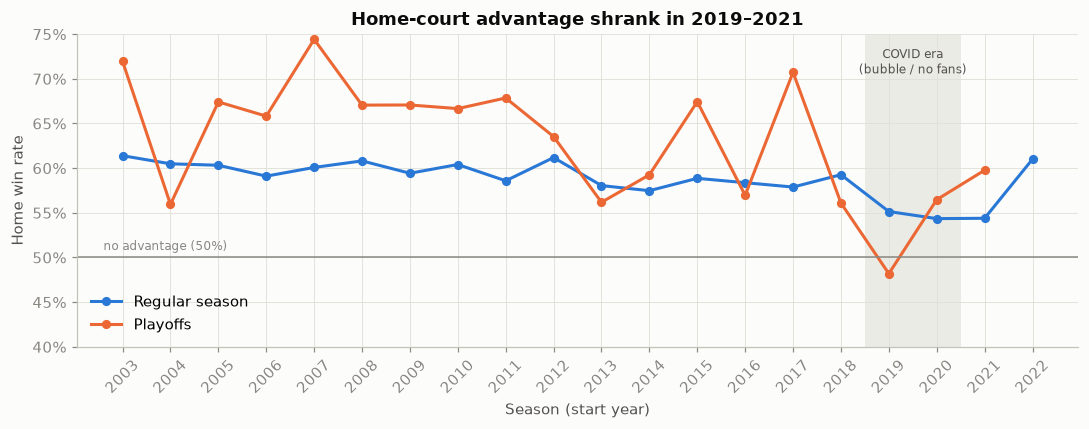

Bubble (neutral-site) games: 172, nominal 'home' win rate 52.3%
Regular-season home win rate 2003-2018: 59.5% vs 2019-2022: 55.4%


In [26]:
hw = games.groupby(["SEASON", "GAME_TYPE"]).HOME_TEAM_WINS.mean().unstack()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(hw.index, hw["Regular Season"], marker="o", markersize=5, color=BLUE, label="Regular season")
ax.plot(hw.index, hw["Playoffs"], marker="o", markersize=5, color=ORANGE, label="Playoffs")
ax.axhline(0.5, color=MUTED, linewidth=1)
ax.text(hw.index.min() - 0.4, 0.505, "no advantage (50%)", va="bottom", fontsize=8, color=MUTED)
ax.axvspan(2018.5, 2020.5, color=GRID, alpha=0.6, linewidth=0)
ax.text(2019.5, 0.735, "COVID era\n(bubble / no fans)", ha="center", va="top", fontsize=8, color=INK2)
ax.set_title("Home-court advantage shrank in 2019–2021")
ax.set_xlabel("Season (start year)")
ax.set_ylabel("Home win rate")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xticks(hw.index)
ax.tick_params(axis="x", rotation=45)
ax.set_ylim(0.40, 0.75)
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

bubble = games[games.NEUTRAL_SITE]
print(f"Bubble (neutral-site) games: {len(bubble)}, nominal 'home' win rate {bubble.HOME_TEAM_WINS.mean():.1%}")
print(f"Regular-season home win rate 2003-2018: {games[(games.SEASON <= 2018) & (games.GAME_TYPE == 'Regular Season')].HOME_TEAM_WINS.mean():.1%}"
      f" vs 2019-2022: {games[(games.SEASON >= 2019) & (games.GAME_TYPE == 'Regular Season')].HOME_TEAM_WINS.mean():.1%}")

### D.2 Scoring trends over time (regular season, per team per game)

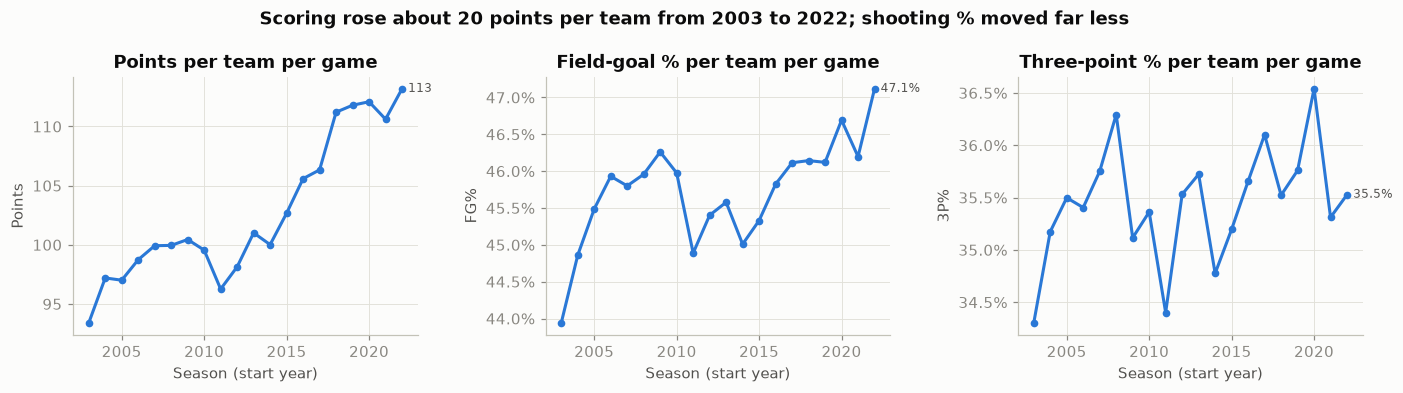

SEASON,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
PTS,93.397,97.199,97.009,98.739,99.923,99.951,100.447,99.550,96.260,98.138,101.009,100.014,102.672,105.591,106.333,111.209,111.798,112.091,110.616,113.188
FG_PCT,0.439,0.449,0.455,0.459,0.458,0.460,0.463,0.460,0.449,0.454,0.456,0.450,0.453,0.458,0.461,0.461,0.461,0.467,0.462,0.471
FG3_PCT,0.343,0.352,0.355,0.354,0.358,0.363,0.351,0.354,0.344,0.355,0.357,0.348,0.352,0.357,0.361,0.355,0.358,0.365,0.353,0.355


In [27]:
tg_reg = tg[tg.GAME_TYPE == "Regular Season"]
trend = tg_reg.groupby("SEASON")[["PTS", "FG_PCT", "FG3_PCT"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
specs = [("PTS", "Points per team per game", "Points", None),
         ("FG_PCT", "Field-goal % per team per game", "FG%", mtick.PercentFormatter(1.0, decimals=1)),
         ("FG3_PCT", "Three-point % per team per game", "3P%", mtick.PercentFormatter(1.0, decimals=1))]
for ax, (col, title, ylab, fmt) in zip(axes, specs):
    ax.plot(trend.index, trend[col], color=BLUE, marker="o", markersize=4)
    ax.set_title(title)
    ax.set_xlabel("Season (start year)")
    ax.set_ylabel(ylab)
    if fmt: ax.yaxis.set_major_formatter(fmt)
    ax.annotate(f"{trend[col].iloc[-1]:.3g}" if col == "PTS" else f"{trend[col].iloc[-1]:.1%}",
                (trend.index[-1], trend[col].iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
plt.suptitle("Scoring rose about 20 points per team from 2003 to 2022; shooting % moved far less", fontweight="bold", color=INK)
plt.tight_layout(); plt.show()
trend.round(3).T

Scoring is **non-stationary**: an average team scored about 93 points per game in 2003-04 and about 113 in 2022-23. FG% rose only from 44% to 47%, and 3P% stayed near 35%. Raw rolling points are therefore not comparable across eras. We will use home-minus-away **differences**, or normalize stats within each season.

### D.3 Team win rates

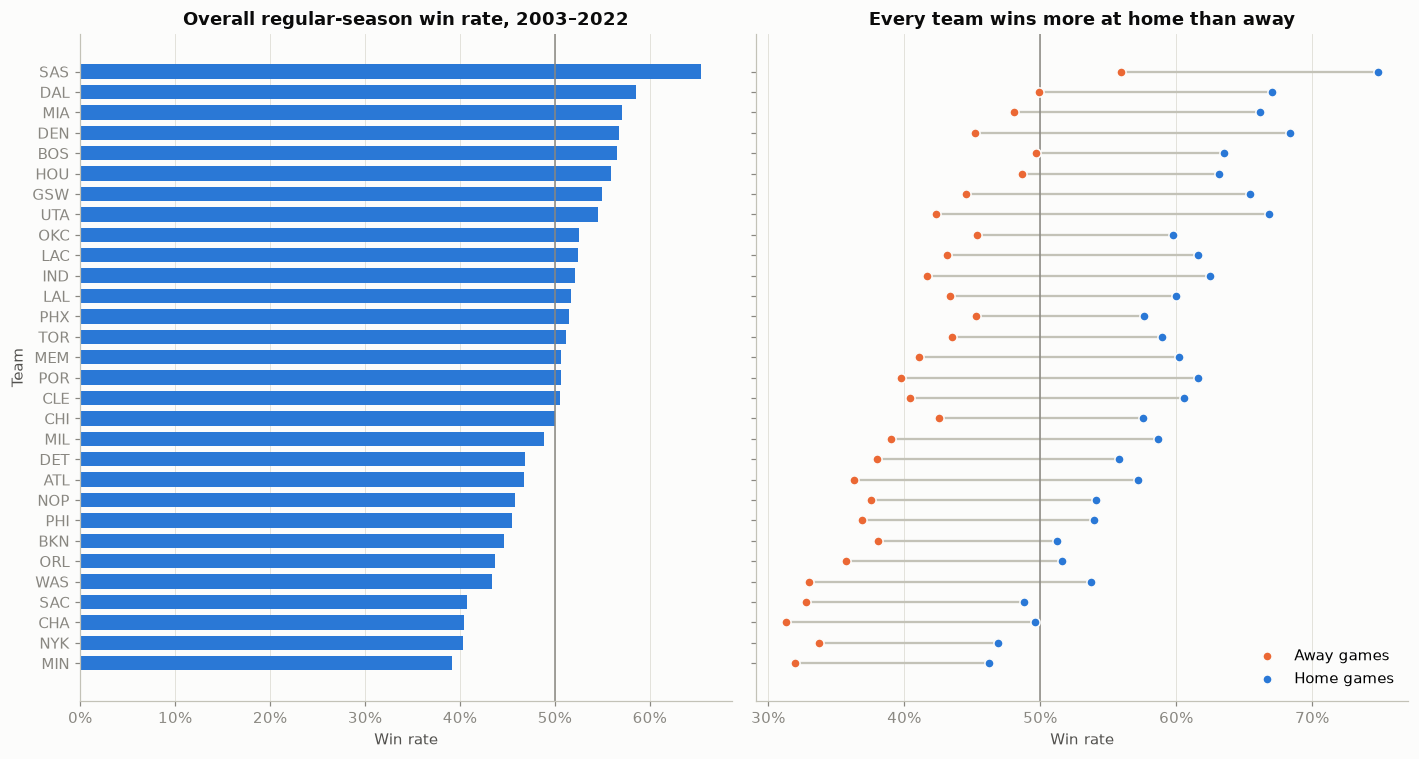

Teams with a higher home than away win rate: 30 of 30
Spread of overall win rate: 39.1% (MIN) to 65.4% (SAS)


In [28]:
abbr_map = raw["teams"].set_index("TEAM_ID").ABBREVIATION
team_rates = (tg_reg.groupby(["TEAM_ID", "IS_HOME"]).WIN.mean().unstack().rename(columns={0: "away", 1: "home"})
                    .assign(overall=tg_reg.groupby("TEAM_ID").WIN.mean()).sort_values("overall"))
team_rates.index = team_rates.index.map(abbr_map)

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
axes[0].barh(team_rates.index, team_rates.overall, color=BLUE, height=0.7)
axes[0].axvline(0.5, color=MUTED, linewidth=1)
axes[0].set_title("Overall regular-season win rate, 2003–2022")
axes[0].set_xlabel("Win rate")
axes[0].set_ylabel("Team")
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].grid(axis="y", visible=False)

y_pos = np.arange(len(team_rates))
axes[1].hlines(y_pos, team_rates.away, team_rates.home, color=AXIS, linewidth=1.5)
axes[1].scatter(team_rates.away, y_pos, color=ORANGE, s=36, label="Away games", zorder=3, edgecolor="#fcfcfb", linewidth=1)
axes[1].scatter(team_rates.home, y_pos, color=BLUE, s=36, label="Home games", zorder=3, edgecolor="#fcfcfb", linewidth=1)
axes[1].axvline(0.5, color=MUTED, linewidth=1)
axes[1].set_title("Every team wins more at home than away")
axes[1].set_xlabel("Win rate")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[1].legend(loc="lower right")
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("Teams with a higher home than away win rate:", int((team_rates.home > team_rates.away).sum()), "of", len(team_rates))
print(f"Spread of overall win rate: {team_rates.overall.min():.1%} ({team_rates.overall.idxmin()}) to "
      f"{team_rates.overall.max():.1%} ({team_rates.overall.idxmax()})")

### D.4 Rest days between a team's games
`REST_DAYS_RAW` is the number of days since the team's previous non-preseason game. A value of 1 means a back-to-back. Gaps longer than two weeks are **offseason gaps** (or the 2020 COVID pause), not real "rest".

,team-games,share
REST_DAYS_RAW,,
2–4 (normal),37718,0.7590
1 (back-to-back),10306,0.2074
5–14 (All-Star break etc.),1051,0.0211
15+ (offseason / COVID pause),591,0.0119
NaN,30,0.0006


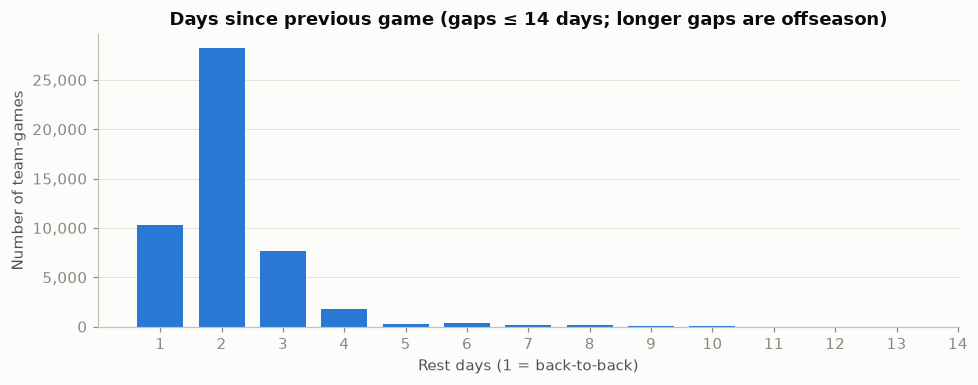

Gaps > 14 days: 591, of which season openers: 569; mid-season ones: 22 (dates: ['2020-07-30', '2020-07-31', '2020-08-01'] ...)
First game of each team's first season has no previous game (NaN): 30

Home win rate by rest advantage (home minus away rest days, clipped to ±3):
rest_adv     -3.0     -2.0      -1.0        0.0       1.0       2.0     3.0
mean        0.527    0.562     0.568      0.585     0.615     0.624    0.59
size      222.000  698.000  3163.000  13029.000  5441.000  1648.000  647.00


In [29]:
rest = fp.rest_days(tg)
tg = tg.join(rest)
r = tg.REST_DAYS_RAW
bins = pd.cut(r, [0, 1, 4, 14, np.inf], labels=["1 (back-to-back)", "2–4 (normal)", "5–14 (All-Star break etc.)", "15+ (offseason / COVID pause)"])
display(bins.value_counts(dropna=False).rename("team-games").to_frame().assign(share=lambda d: (d["team-games"] / d["team-games"].sum()).round(4)))

within = r[r <= 14]
counts_rest = within.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(counts_rest.index, counts_rest.values, color=BLUE, width=0.75)
ax.set_title("Days since previous game (gaps ≤ 14 days; longer gaps are offseason)")
ax.set_xlabel("Rest days (1 = back-to-back)")
ax.set_ylabel("Number of team-games")
ax.set_xticks(range(1, 15))
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

long_gaps = tg[r > 14]
print(f"Gaps > 14 days: {len(long_gaps):,}, of which season openers: {long_gaps.SEASON_OPENER.sum():,}; "
      f"mid-season ones: {(long_gaps.SEASON_OPENER == 0).sum()} (dates: {sorted(long_gaps.loc[long_gaps.SEASON_OPENER == 0, 'GAME_DATE'].dt.strftime('%Y-%m-%d').unique())[:6]} ...)")
print("First game of each team's first season has no previous game (NaN):", int(r.isna().sum()))

# Descriptive only: home win rate by rest advantage (home rest - away rest, capped at 7)
rest_game = tg.pivot_table(index="GAME_ID", columns="IS_HOME", values="REST_DAYS").rename(columns={0: "away", 1: "home"})
rest_game = rest_game.join(games.set_index("GAME_ID").HOME_TEAM_WINS)
rest_game["rest_adv"] = (rest_game.home - rest_game.away).clip(-3, 3)
print("\nHome win rate by rest advantage (home minus away rest days, clipped to ±3):")
print(rest_game.groupby("rest_adv").HOME_TEAM_WINS.agg(["mean", "size"]).round(3).T.to_string())

### D.5 Correlations among the numeric game stats
These are same-game stats. The heatmap shows how they relate to each other and to the outcome. Section E explains why none of them can be a feature for that same game.

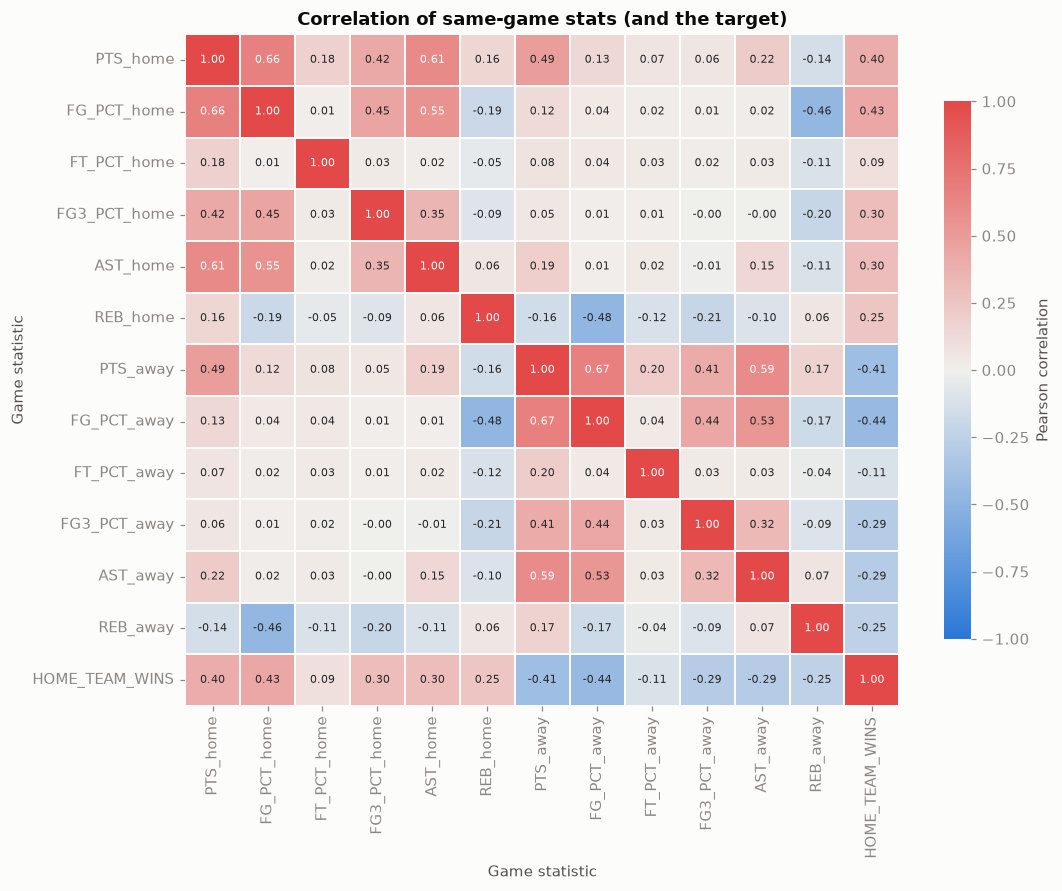

Correlation with HOME_TEAM_WINS:
FG_PCT_away    -0.438
PTS_away       -0.412
AST_away       -0.294
FG3_PCT_away   -0.294
REB_away       -0.254
FT_PCT_away    -0.111
FT_PCT_home     0.093
REB_home        0.248
FG3_PCT_home    0.301
AST_home        0.303
PTS_home        0.397
FG_PCT_home     0.434


In [30]:
corr_cols = dl.SAME_GAME_COLUMNS + ["HOME_TEAM_WINS"]
corr = games[corr_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8.2))
sns.heatmap(corr, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=1, linecolor="#fcfcfb", cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
ax.grid(False)
ax.set_title("Correlation of same-game stats (and the target)")
ax.set_xlabel("Game statistic")
ax.set_ylabel("Game statistic")
plt.tight_layout(); plt.show()
print("Correlation with HOME_TEAM_WINS:")
print(corr["HOME_TEAM_WINS"].drop("HOME_TEAM_WINS").sort_values().round(3).to_string())

- Shooting efficiency (FG%) is the stat most correlated with winning, with opposite signs for home and away.
- Points and assists are strongly correlated with FG%.
- Rebounds correlate *negatively* with the opponent's FG%, because more misses create more rebounds.

These relationships suggest that **rolling shooting efficiency and point differential** should be the most useful *historical* features.

## E. Leakage check

### E.1 Columns that are same-game results

In [31]:
leak_table = pd.DataFrame([
    {"column": c, "side": c.rsplit("_", 1)[1], "meaning": dl.COLUMN_DESCRIPTIONS["games"][c],
     "allowed_as_feature_for_same_game": "NO: recorded during or after the game"}
    for c in dl.SAME_GAME_COLUMNS
])
leak_table

,column,side,meaning,allowed_as_feature_for_same_game
0,PTS_home,home,Points scored by the home team in this game.,NO: recorded during or after the game
1,FG_PCT_home,home,Home field-goal percentage in this game (0-1).,NO: recorded during or after the game
2,FT_PCT_home,home,Home free-throw percentage in this game (0-1).,NO: recorded during or after the game
3,FG3_PCT_home,home,Home three-point percentage in this game (0-1).,NO: recorded during or after the game
4,AST_home,home,Home assists in this game.,NO: recorded during or after the game
5,REB_home,home,Home total rebounds in this game.,NO: recorded during or after the game
6,PTS_away,away,Points scored by the away team in this game.,NO: recorded during or after the game
7,FG_PCT_away,away,Away field-goal percentage in this game (0-1).,NO: recorded during or after the game
8,FT_PCT_away,away,Away free-throw percentage in this game (0-1).,NO: recorded during or after the game
9,FG3_PCT_away,away,Away three-point percentage in this game (0-1).,NO: recorded during or after the game


Also off-limits for the same game:
- **all of `games_details.csv`**, which is player box scores of that game;
- **`ranking.csv` rows dated on the game day**, which already include the result (B.5).

Allowed for the same game:
- `GAME_DATE_EST`, `SEASON`, `HOME_TEAM_ID`, `VISITOR_TEAM_ID`, and the game type, all known in advance;
- anything computed only from **earlier** games.

### E.2 Demonstration: how well do same-game stats "predict" the winner?
No model is trained. Each rule just checks the sign of the home-minus-away difference.

In [32]:
demo = []
for s in dl.SAME_GAME_STATS:
    diff = games[f"{s}_home"] - games[f"{s}_away"]
    pred = (diff > 0).astype(int)
    demo.append({"rule": f"home wins if {s}_home > {s}_away", "accuracy": round((pred == games.HOME_TEAM_WINS).mean(), 4)})
demo.append({"rule": "always predict home win (majority baseline)", "accuracy": round(games.HOME_TEAM_WINS.mean(), 4)})
display(pd.DataFrame(demo).sort_values("accuracy", ascending=False).set_index("rule"))

# Same-day standings leak too: did the home team's W go up between yesterday's and today's snapshot?
w = ranking.set_index(["TEAM_ID", "SEASON", "STANDINGSDATE"])["W"]
regg = games[games.GAME_TYPE == "Regular Season"]
w_today = w.reindex(pd.MultiIndex.from_arrays([regg.HOME_TEAM_ID, regg.SEASON, regg.GAME_DATE])).to_numpy()
w_prev = w.reindex(pd.MultiIndex.from_arrays([regg.HOME_TEAM_ID, regg.SEASON, regg.GAME_DATE - pd.Timedelta(days=1)])).to_numpy()
ok = ~np.isnan(w_today) & ~np.isnan(w_prev)
print(f"Rule 'home W in SAME-DAY standings > previous day' matches HOME_TEAM_WINS in "
      f"{np.mean((w_today[ok] > w_prev[ok]).astype(int) == regg.HOME_TEAM_WINS.to_numpy()[ok]):.2%} of {ok.sum():,} games")

,accuracy
rule,
home wins if PTS_home > PTS_away,1.0000
home wins if FG_PCT_home > FG_PCT_away,0.7956
home wins if AST_home > AST_away,0.7009
home wins if FG3_PCT_home > FG3_PCT_away,0.6847
home wins if REB_home > REB_away,0.6518
always predict home win (majority baseline),0.5910
home wins if FT_PCT_home > FT_PCT_away,0.5571


Rule 'home W in SAME-DAY standings > previous day' matches HOME_TEAM_WINS in 100.00% of 23,185 games


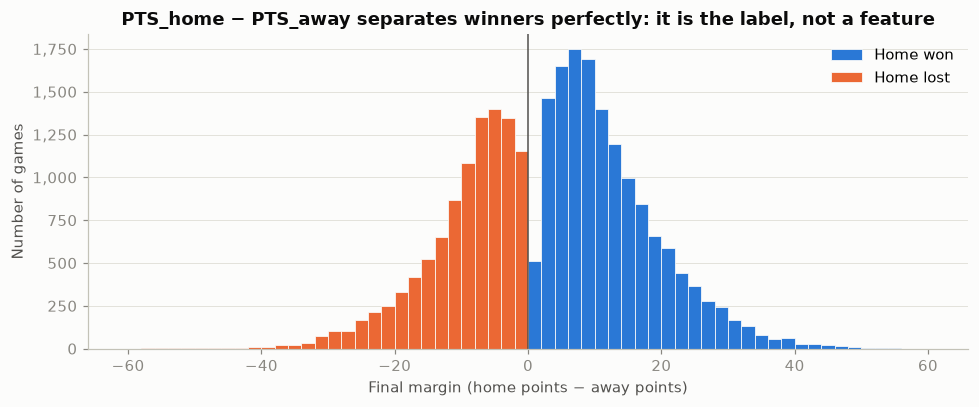

Ties in the data: 0


In [33]:
margin = games.PTS_home - games.PTS_away
fig, ax = plt.subplots(figsize=(9, 3.8))
bins_m = np.arange(-60, 62, 2)
ax.hist(margin[games.HOME_TEAM_WINS == 1], bins=bins_m, color=BLUE, label="Home won", edgecolor="#fcfcfb", linewidth=0.5)
ax.hist(margin[games.HOME_TEAM_WINS == 0], bins=bins_m, color=ORANGE, label="Home lost", edgecolor="#fcfcfb", linewidth=0.5)
ax.axvline(0, color=INK2, linewidth=1)
ax.set_title("PTS_home − PTS_away separates winners perfectly: it is the label, not a feature")
ax.set_xlabel("Final margin (home points − away points)")
ax.set_ylabel("Number of games")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend()
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print("Ties in the data:", int((margin == 0).sum()))

The point margin determines the label exactly (100% accuracy, no ties). FG% alone already gets about 80%. If any of these leaked into training, the project would report a meaningless ~80–100% accuracy. Realistic pre-game models usually reach around 65–70%.

## F. Feasibility of the planned pre-game features

All features come from `src/features_prototype.py` and are built on the **full** cleaned data. Every feature for a game uses only **earlier dates**:

| Feature family | Source | How leakage is prevented |
|---|---|---|
| Rolling averages of the previous N = 5, 10 games (win %, points for/against, margin, FG%, 3P%, FT%, AST, REB) | `games.csv` | `shift(1)` before `rolling(N)`, per team and season |
| Rest days, back-to-back flag, season-opener flag | `games.csv` dates | difference to the *previous* game date |
| Win/loss streak entering the game | `games.csv` | streak value stored *before* adding this game's result |
| Season record so far | `games.csv` | cumulative wins minus the current game |
| Pre-game standings (G, W, L, W%, home and road W%) | `ranking.csv` | `merge_asof(..., allow_exact_matches=False)`: latest snapshot **strictly before** game day, same season |
| Elo rating (K=20, +100 home, 75% carry-over between seasons) | `games.csv` | rating read before it is updated with this game's result |

In [34]:
features = fp.build_game_features(games, ranking)
print("Feature matrix:", features.shape, "(one row per game)")
groups = {
    "rolling (N=5,10)": [c for c in features.columns if "_LAST" in c and not c.startswith("DIFF")],
    "rest":             [c for c in features.columns if any(k in c for k in ("REST", "BACK_TO_BACK", "OPENER")) and not c.startswith("DIFF")],
    "streak / record":  [c for c in features.columns if any(k in c for k in ("STREAK", "SEASON_G", "SEASON_W_PCT")) and not c.startswith("DIFF")],
    "standings":        [c for c in features.columns if "_ST_" in c and not c.startswith("DIFF")],
    "elo":              [c for c in features.columns if c.startswith("ELO")],
    "home-away diffs":  [c for c in features.columns if c.startswith("DIFF")],
}
display(pd.DataFrame({"n_columns": {k: len(v) for k, v in groups.items()},
                      "examples": {k: ", ".join(v[:4]) + (" ..." if len(v) > 4 else "") for k, v in groups.items()}}))
na = features.select_dtypes("number").isna().mean().sort_values(ascending=False)
print("Highest missing rates (early-season games have little or no history yet, e.g. no home game played so far):")
print(na.head(5).round(4).to_string())

Feature matrix: (24848, 80) (one row per game)


,n_columns,examples
"rolling (N=5,10)",36,"HOME_WIN_LAST5, HOME_PTS_LAST5, HOME_PTS_OPP_LAST5, HOME_PLUS_MINUS_LAST5 ..."
rest,8,"HOME_REST_DAYS_RAW, HOME_REST_DAYS, HOME_BACK_TO_BACK, HOME_SEASON_OPENER ..."
streak / record,6,"HOME_STREAK, HOME_SEASON_G, HOME_SEASON_W_PCT, AWAY_STREAK ..."
standings,14,"HOME_ST_DATE_USED, HOME_ST_G, HOME_ST_W, HOME_ST_L ..."
elo,3,"ELO_HOME, ELO_AWAY, ELO_PROB_HOME"
home-away diffs,13,"DIFF_WIN_LAST5, DIFF_PTS_LAST5, DIFF_PTS_OPP_LAST5, DIFF_PLUS_MINUS_LAST5 ..."


Highest missing rates (early-season games have little or no history yet, e.g. no home game played so far):
AWAY_ST_ROAD_W_PCT    0.0241
HOME_ST_HOME_W_PCT    0.0241
HOME_ST_ROAD_W_PCT    0.0184
AWAY_ST_HOME_W_PCT    0.0171
DIFF_PTS_LAST10       0.0138


### F.1 Rolling averages: hand-checked worked example
Below are one team's games around game #12 of a season. The prototype's `WIN_LAST5` and `PTS_LAST5` must equal the mean over the **five previous** games, with the current game excluded.

In [35]:
tf = fp.team_features(games, ranking)
tgf = tg[["GAME_ID", "TEAM_ID", "SEASON", "GAME_DATE", "WIN", "PTS"]].merge(
    tf[["GAME_ID", "TEAM_ID", "WIN_LAST5", "PTS_LAST5", "STREAK", "REST_DAYS_RAW", "ST_DATE_USED", "ST_G", "ST_W", "SEASON_G"]],
    on=["GAME_ID", "TEAM_ID"])
team_id = raw["teams"].set_index("ABBREVIATION").loc["GSW", "TEAM_ID"]
ex = tgf[(tgf.TEAM_ID == team_id) & (tgf.SEASON == 2015)].reset_index(drop=True)
display(ex.loc[6:12, ["GAME_DATE", "WIN", "PTS", "WIN_LAST5", "PTS_LAST5", "STREAK", "REST_DAYS_RAW", "ST_DATE_USED", "ST_G", "ST_W"]])

t = 12
assert np.isclose(ex.loc[t, "WIN_LAST5"], ex.loc[t - 5:t - 1, "WIN"].mean())
assert np.isclose(ex.loc[t, "PTS_LAST5"], ex.loc[t - 5:t - 1, "PTS"].mean())
assert ex.loc[0, ["WIN_LAST5", "PTS_LAST5"]].isna().all(), "first game of a season must have no rolling history"

# Global property: for every team-game the rolling WIN_LAST1 equals the previous game's result (same team, same season)
check = fp.rolling_form(tg, windows=(1,), stats=["WIN"])
prev_win = tg.groupby(["TEAM_ID", "SEASON"]).WIN.shift(1)
assert check["WIN_LAST1"].equals(prev_win.astype(float)), "WIN_LAST1 must be exactly the previous game's result"
print("✓ rolling averages use only the previous N games of the same team (current game excluded)")

,GAME_DATE,WIN,PTS,WIN_LAST5,PTS_LAST5,STREAK,REST_DAYS_RAW,ST_DATE_USED,ST_G,ST_W
6,2015-11-07,1,103.0,1.0,119.2,6,1.0,2015-11-06,6.0,6.0
7,2015-11-09,1,109.0,1.0,117.4,7,2.0,2015-11-08,7.0,7.0
8,2015-11-11,1,100.0,1.0,112.4,8,2.0,2015-11-10,8.0,8.0
9,2015-11-12,1,129.0,1.0,108.6,9,1.0,2015-11-11,9.0,9.0
10,2015-11-14,1,107.0,1.0,112.0,10,2.0,2015-11-13,10.0,10.0
11,2015-11-17,1,115.0,1.0,109.6,11,3.0,2015-11-16,11.0,11.0
12,2015-11-19,1,124.0,1.0,112.0,12,2.0,2015-11-18,12.0,12.0


✓ rolling averages use only the previous N games of the same team (current game excluded)


### F.2 Rest days, streaks, season record

In [36]:
prev_date = tg.groupby("TEAM_ID").GAME_DATE.shift(1)
assert (prev_date.dropna() < tg.loc[prev_date.notna(), "GAME_DATE"]).all(), "previous game must be strictly earlier"
assert (tf.REST_DAYS_RAW.dropna() >= 1).all(), "no team plays twice on one date"
assert not tg.duplicated(["TEAM_ID", "GAME_DATE"]).any()
print("✓ rest days: previous game is always on an earlier date (min rest =", int(tf.REST_DAYS_RAW.min()), "day)")

# streak: the GSW 2015-16 team started 24-0. Its streak entering game k must be k (k = 0..24)
assert ex.loc[:24, "STREAK"].tolist() == list(range(25)), "GSW 2015-16 streak should read 0,1,...,24"
assert ex.loc[25, "STREAK"] == -1, "after the first loss (game 25), streak entering game 26 is -1"
openers = tf[tf.SEASON_OPENER == 1]
assert (openers.STREAK == 0).all() and (openers.SEASON_G == 0).all()
print("✓ streak and season record are computed before the current result (e.g. GSW 2015-16: 0, 1, ..., 24, then -1)")

✓ rest days: previous game is always on an earlier date (min rest = 1 day)
✓ streak and season record are computed before the current result (e.g. GSW 2015-16: 0, 1, ..., 24, then -1)


### F.3 Pre-game standings from `ranking.csv` (day before)

In [37]:
used = tf.ST_DATE_USED
assert (used.dropna() < tf.loc[used.notna(), "GAME_DATE"]).all(), "standings snapshot must be dated strictly before the game"
assert tf.loc[used.isna(), "SEASON_OPENER"].eq(1).all(), "only season openers may lack a snapshot (-> 0-0 record)"
day_before = (tf.GAME_DATE - used).dt.days
print("Days between snapshot used and game day:", day_before.value_counts().sort_index().to_dict(),
      "| openers without snapshot:", int(used.isna().sum()))
print("Games using an older-than-1-day snapshot:", sorted(tf.loc[day_before > 1, "GAME_DATE"].dt.strftime("%Y-%m-%d").unique()), "(bubble restart)")

# The snapshot must describe exactly the games played BEFORE this one (regular season)
reg_tf = tf[tf.GAME_TYPE == "Regular Season"]
mismatch = reg_tf[reg_tf.ST_G != reg_tf.SEASON_G]
known_gap = (mismatch.SEASON == 2022) & mismatch.TEAM_ID.isin(abbr_map[abbr_map.isin(["ORL", "IND"])].index)
print(f"Regular-season team-games where snapshot G != games played before: {len(mismatch)} "
      f"(all explained by the one missing 2022 ORL–IND game: {bool(known_gap.all())})")
assert known_gap.all()
assert (mismatch.ST_G == mismatch.SEASON_G + 1).all(), "the only gap is +1 game from the missing GAME_ID"
print("✓ standings come from the previous day and never include the game being predicted")

Days between snapshot used and game day: {1.0: 49578, 9.0: 4} | openers without snapshot: 114
Games using an older-than-1-day snapshot: ['2020-07-30'] (bubble restart)
Regular-season team-games where snapshot G != games played before: 33 (all explained by the one missing 2022 ORL–IND game: True)
✓ standings come from the previous day and never include the game being predicted


### F.4 Elo ratings

In [38]:
elo = features[["ELO_HOME", "ELO_AWAY", "ELO_PROB_HOME"]]
assert elo.notna().all().all() and elo.ELO_PROB_HOME.between(0, 1).all()
first_game = games.iloc[0].GAME_ID
assert (features.loc[first_game, ["ELO_HOME", "ELO_AWAY"]] == 1500).all(), "the very first game starts from 1500"

# end-of-regular-season Elo leaderboard 2015-16 as a sanity check (GSW 73-9 should be near the top)
season_rows = games[(games.SEASON == 2015)]
last_ids = season_rows.groupby("HOME_TEAM_ID").GAME_ID.last()
top = features.loc[last_ids.values, "ELO_HOME"].set_axis(last_ids.index.map(abbr_map)).sort_values(ascending=False)
print("Pre-game Elo at each team's last 2015-16 home game (top 5):", top.head(5).round(0).to_dict())

# Descriptive signal check (no fitting): home win rate by pre-game Elo-difference quintile, training seasons only
tr = features.join(games.set_index("GAME_ID")[["HOME_TEAM_WINS", "SPLIT"]])
tr = tr[tr.SPLIT == "train"]
q = pd.qcut(tr.DIFF_ELO, 5, labels=["Q1 (away much stronger)", "Q2", "Q3", "Q4", "Q5 (home much stronger)"])
print("\nHome win rate by Elo-difference quintile (train seasons):")
print(tr.groupby(q, observed=True).HOME_TEAM_WINS.mean().round(3).to_string())
print("✓ Elo is computable game by game from past results only")

Pre-game Elo at each team's last 2015-16 home game (top 5): {'GSW': 1796.0, 'SAS': 1759.0, 'OKC': 1708.0, 'CLE': 1705.0, 'LAC': 1625.0}

Home win rate by Elo-difference quintile (train seasons):
DIFF_ELO
Q1 (away much stronger)    0.343
Q2                         0.499
Q3                         0.608
Q4                         0.716
Q5 (home much stronger)    0.832
✓ Elo is computable game by game from past results only


### F.5 Global leakage test: perturb the present, delete the future
`assert_no_leakage` recomputes **all** features many times. Each time it picks a cutoff date D and then:
- **deletes every game after D**,
- **flips the result of every game on D** by swapping the home and away stat lines,
- **scrambles every `ranking.csv` row dated D or later**.

If any feature of a game on or before D changed, that feature used its own result, a later game, or a same-day or later standings row, and the test fails. We use 40 random cutoff dates plus every season's opening night.

To show the test can actually catch something, we also run it on a deliberately leaky feature: a rolling mean computed **without** `shift(1)`. That run must fail.

In [39]:
all_dates = np.sort(games.GAME_DATE.unique())
cutoffs = list(rng.choice(all_dates, size=40, replace=False)) + list(games.groupby("SEASON").GAME_DATE.min())
n_checked = fp.assert_no_leakage(fp.build_game_features, games, cutoffs, ranking)
print(f"✓ PASSED: {len(cutoffs)} cutoff dates, {n_checked:,} game-feature rows compared, all {features.shape[1]} features identical")

try:
    fp.assert_no_leakage(fp.leaky_rolling_example, games, cutoffs[:5])
    raise RuntimeError("the leaky feature was NOT caught: the test would be useless")
except AssertionError:
    print("✓ sanity check: the deliberately leaky feature (rolling mean without shift) is caught by the same test")

✓ PASSED: 60 cutoff dates, 775,199 game-feature rows compared, all 80 features identical
✓ sanity check: the deliberately leaky feature (rolling mean without shift) is caught by the same test


## G. Open questions and risks for the professor

1. **Which games are in scope?** Proposal: train and evaluate on regular season + play-in + playoffs (24,848 games), dropping preseason. Alternative: regular season only (23,244 games), with playoff games used only as feature history. Is either preferred?
2. **COVID-era distribution shift.** The home win rate fell from about 59–61% per season (2003–2018) to about 55% in 2019–2021; the partial 2022-23 season is back at 61%. The 172 bubble games had *no* real home team. Keep them with a `NEUTRAL_SITE` flag, drop them, or report them separately?
3. **The test set is unusual.** Every test season (2019–2022) is shortened or affected by COVID, and 2022-23 is partial. Is it acceptable to also report results on 2021-22 alone (a normal season) or with a rolling-origin evaluation (train ≤ S−1, test S, for each S)?
4. **Era drift in raw stats.** Scoring rose about 20 points per team per game from 2003 to 2022. We plan home-minus-away differences and within-season normalization. Is that sufficient?
5. **Cold start.** Elo begins at 1500 for everyone in 2003, and every team's first game of a season has no rolling history. Options: treat 2003 as warm-up only, carry rolling windows across seasons, or impute. Which is preferred?
6. **Data errors we handle but cannot fully fix:**
   - two duplicate games with conflicting box-score values;
   - 40 box scores (mostly 2003–04) whose player points do not sum to the team score;
   - 12 rows with negative minutes;
   - one missing 2022 game.

   None of these affect the label.
7. **Metadata is a 2019 snapshot.** `teams.csv` (coach, GM, arena) and `players.csv` (2009–2019 only) cannot be used as historical features without leaking or mis-dating information. We do not plan to use them.
8. **Player-availability features** (e.g., stars missing) could be built from `games_details` DNP comments of *previous* games. However, that is not true pre-game injury information. Is it worth the complexity?
9. **Metric choice.** With 59% home wins, accuracy should be reported next to the majority baseline, plus log-loss / Brier score and ROC-AUC. Is there a required metric?

## Key numbers to say out loud

In [40]:
key = {
    "Files": "5 CSVs (games, games_details, ranking, players, teams)",
    "games.csv raw": f"{len(games_raw):,} rows × {games_raw.shape[1]} columns ({games_raw.GAME_ID.nunique():,} unique games)",
    "games_details.csv": f"{len(gd):,} player rows × {gd.shape[1]} columns",
    "ranking.csv": f"{len(rk):,} rows × {raw['ranking'].shape[1]} columns ({rk.STANDINGSDATE.nunique():,} daily snapshots)",
    "Seasons": f"{games.SEASON.nunique()} ({games.SEASON.min()}-{str(games.SEASON.min() + 1)[2:]} to {games.SEASON.max()}-{str(games.SEASON.max() + 1)[2:]}, last one partial)",
    "Modeling table": f"{len(games):,} games (= training examples overall) after removing 29 duplicates, 99 no-stat games, preseason",
    "Split (train / val / test)": " / ".join(f"{int(split_table.loc[p, 'games']):,}" for p in ["train", "validation", "test"])
                                  + "  (2003-16 / 2017-18 / 2019-22)",
    "Label balance": f"{games.HOME_TEAM_WINS.mean():.1%} home wins / {1 - games.HOME_TEAM_WINS.mean():.1%} away wins",
    "Majority baseline accuracy (val / test)": f"{baseline.loc['validation', 'accuracy']:.1%} / {baseline.loc['test', 'accuracy']:.1%}",
    "Planned features": f"{features.shape[1]} prototype columns: rolling last-5/10 form, rest days & back-to-backs, streak, "
                        "season record, previous-day standings, Elo, plus home-minus-away diffs",
}
pd.Series(key, name="value").to_frame()

,value
Files,"5 CSVs (games, games_details, ranking, players, teams)"
games.csv raw,"26,651 rows × 21 columns (26,622 unique games)"
games_details.csv,"668,628 player rows × 29 columns"
ranking.csv,"210,342 rows × 13 columns (7,023 daily snapshots)"
Seasons,"20 (2003-04 to 2022-23, last one partial)"
Modeling table,"24,848 games (= training examples overall) after removing 29 duplicates, 99 no-stat games, preseason"
Split (train / val / test),"18,110 / 2,624 / 4,114 (2003-16 / 2017-18 / 2019-22)"
Label balance,59.1% home wins / 40.9% away wins
Majority baseline accuracy (val / test),58.9% / 55.4%
Planned features,"80 prototype columns: rolling last-5/10 form, rest days & back-to-backs, streak, season record, previous-d..."
